# 04a – ANN (Multi-Layer Perceptron)
`text → TF-IDF (50k terms) → L2 normalise → Dense + ReLU → Dropout → Dense(8) + Softmax`, weighted cross-entropy, Adam, early stopping.

Preliminary validation experiments (256 units): raw TF-IDF 20k 0.835 · L2-normalised 20k 0.849 · **L2-normalised 50k 0.855** · 512→128 units 0.840.

In [1]:
import os, sys, time, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import f1_score

from src.data import load_split, LABELS, SEED, RESULTS_DIR, ROOT as PROJECT_ROOT
from src.plotting import set_style, save, SERIES, TEXT, TEXT_SECONDARY
from src.evaluate import record_metrics, per_class_report, save_predictions, plot_confusion_matrix
from src.diagrams import draw_chain

set_style()
keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

train, val, test = load_split("train"), load_split("val"), load_split("test")
label_to_id = {l: i for i, l in enumerate(LABELS)}
y_train, y_val, y_test = (d.label.map(label_to_id).to_numpy() for d in (train, val, test))

counts = np.bincount(y_train, minlength=len(LABELS))
class_weight = {i: len(y_train) / (len(LABELS) * c) for i, c in enumerate(counts)}
pd.Series(class_weight, index=range(len(LABELS))).set_axis(LABELS).round(2).rename("class weight").to_frame()

TensorFlow 2.21.0 | Keras 3.15.1


,class weight
Hardware,0.44
HR Support,0.55
Access,0.83
Miscellaneous,0.84
Storage,2.14
Purchase,2.62
Internal Project,2.80
Administrative rights,3.36


## 1. TF-IDF vectorizer (fit on train only)

In [2]:
VOCAB_SIZE = 50_000
vectorizer = layers.TextVectorization(max_tokens=VOCAB_SIZE, ngrams=2, output_mode="tf_idf", standardize=None)
vectorizer.adapt(tf.constant(train.text.values))
assert vectorizer.vocabulary_size() == VOCAB_SIZE
print("Vocabulary size:", vectorizer.vocabulary_size())
print("Sample entries:", vectorizer.get_vocabulary()[1:15])

# The vectorizer lives *inside* the model, so the datasets hold raw strings and the saved model accepts text directly.
def to_ds(df, y, shuffle=False, batch=64):
    ds = tf.data.Dataset.from_tensor_slices((df.text.values, y))
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds = to_ds(train, y_train, shuffle=True)
val_ds, test_ds = to_ds(val, y_val), to_ds(test, y_test)

Vocabulary size: 50000
Sample entries: [np.str_('please'), np.str_('pm'), np.str_('hi'), np.str_('regards'), np.str_('thank'), np.str_('for'), np.str_('hello'), np.str_('you'), np.str_('re'), np.str_('thanks'), np.str_('sent'), np.str_('access'), np.str_('kind'), np.str_('kind regards')]


## 2. Compare network sizes on validation

In [3]:
def trainable_params(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

def build_ann(hidden, dropout):
    inputs = keras.Input(shape=(), dtype="string", name="text")
    x = vectorizer(inputs)
    x = layers.UnitNormalization(name="l2_normalise")(x)
    for i, units in enumerate(hidden):
        x = layers.Dense(units, activation="relu", name=f"hidden_{i + 1}")(x)
        x = layers.Dropout(dropout, name=f"dropout_{i + 1}")(x)
    outputs = layers.Dense(len(LABELS), activation="softmax", name="softmax")(x)
    model = keras.Model(inputs, outputs, name="ann")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

CONFIGS = {"small: 128": [128], "medium: 256": [256], "deep: 512 → 128": [512, 128]}
runs = {}
for name, hidden in CONFIGS.items():
    keras.utils.set_random_seed(SEED)
    model = build_ann(hidden, dropout=0.5)
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=class_weight, verbose=0,
                     callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)])
    secs = time.time() - t0
    val_pred = model.predict(val_ds, verbose=0).argmax(1)
    runs[name] = dict(model=model, history=hist.history, seconds=secs,
                      val_macro_f1=f1_score(y_val, val_pred, average="macro"),
                      val_accuracy=(val_pred == y_val).mean(), params=trainable_params(model),
                      best_epoch=int(np.argmin(hist.history["val_loss"])) + 1, epochs_run=len(hist.history["loss"]))
    print(f"{name:20s} val macro-F1 {runs[name]['val_macro_f1']:.4f} | acc {runs[name]['val_accuracy']:.4f} | "
          f"best epoch {runs[name]['best_epoch']}/{runs[name]['epochs_run']} | {secs:.0f}s")

tuning = pd.DataFrame({k: {c: v[c] for c in ["val_macro_f1", "val_accuracy", "params", "best_epoch", "seconds"]}
                       for k, v in runs.items()}).T
tuning.to_csv(RESULTS_DIR / "ann_tuning.csv")
tuning

/Users/chmo4618exc/ML_PROJECT/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


small: 128           val macro-F1 0.8534 | acc 0.8550 | best epoch 7/9 | 104s


/Users/chmo4618exc/ML_PROJECT/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


medium: 256          val macro-F1 0.8564 | acc 0.8557 | best epoch 4/6 | 185s


/Users/chmo4618exc/ML_PROJECT/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


deep: 512 → 128      val macro-F1 0.8330 | acc 0.8381 | best epoch 2/4 | 228s


,val_macro_f1,val_accuracy,params,best_epoch,seconds
small: 128,0.853388,0.854974,6401160.0,7.0,103.583598
medium: 256,0.856363,0.855683,12802312.0,4.0,184.970712
deep: 512 → 128,0.832965,0.838087,25667208.0,2.0,227.769728


In [4]:
best_name = max(runs, key=lambda k: runs[k]["val_macro_f1"])
best = runs[best_name]
ann = best["model"]
print("Selected:", best_name)
ann.summary()

Selected: medium: 256


Model: "ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text (InputLayer)               │ (None)                 │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ text_vectorization              │ (None, 50000)          │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l2_normalise                    │ (None, 50000)          │             0 │
│ (UnitNormalization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 256)            │    12,800,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Dense)                 │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,406,938 (146.51 MB)

 Trainable params: 12,802,312 (48.84 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 25,604,626 (97.67 MB)

## 3. Architecture diagram

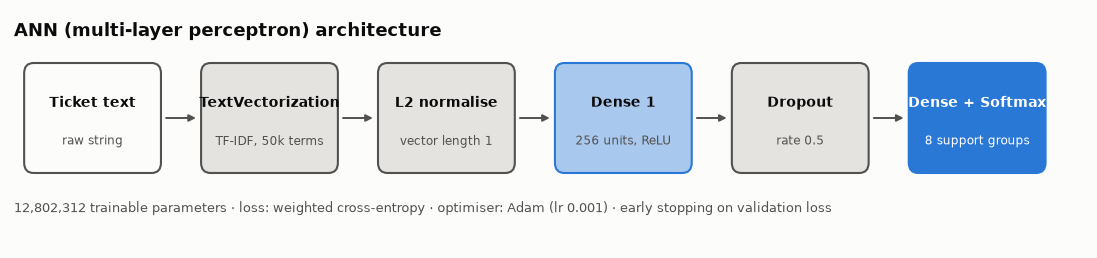

In [5]:
hidden = CONFIGS[best_name]
chain = [("io", "Ticket text", "raw string"),
         ("prep", "TextVectorization", f"TF-IDF, {VOCAB_SIZE // 1000}k terms"),
         ("prep", "L2 normalise", "vector length 1")]
for i, u in enumerate(hidden):
    chain += [("layer", f"Dense {i + 1}", f"{u} units, ReLU"), ("prep", "Dropout", "rate 0.5")]
chain += [("output", "Dense + Softmax", "8 support groups")]
fig = draw_chain(chain, "ANN (multi-layer perceptron) architecture", "12_ann_architecture",
                 subtitle=f"{trainable_params(ann):,} trainable parameters · loss: weighted cross-entropy · optimiser: Adam (lr 0.001) · early stopping on validation loss")
plt.show()

## 4. Training curves
Early stopping keeps the epoch with the lowest validation loss.

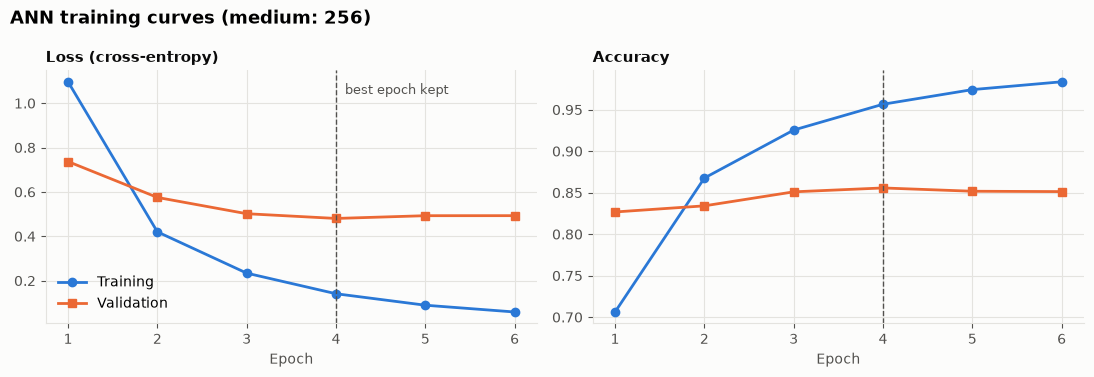

In [6]:
h = best["history"]
epochs = np.arange(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, key, lab in [(axes[0], "loss", "Loss (cross-entropy)"), (axes[1], "accuracy", "Accuracy")]:
    ax.plot(epochs, h[key], color="#2a78d6", marker="o", markersize=6, linewidth=2, label="Training")
    ax.plot(epochs, h[f"val_{key}"], color="#eb6834", marker="s", markersize=6, linewidth=2, label="Validation")
    ax.axvline(best["best_epoch"], color=TEXT_SECONDARY, linestyle="--", linewidth=1)
    ax.set_xlabel("Epoch")
    ax.set_title(lab, fontsize=11)
    ax.set_xticks(epochs)
axes[0].text(best["best_epoch"] + 0.1, axes[0].get_ylim()[1] * 0.95, "best epoch kept", fontsize=9, color=TEXT_SECONDARY, va="top")
axes[0].legend(frameon=False)
fig.suptitle(f"ANN training curves ({best_name})", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "13_ann_training_curves")
plt.show()

## 5. Test results

In [7]:
val_proba = ann.predict(val_ds, verbose=0)
test_proba = ann.predict(test_ds, verbose=0)
val_pred = np.array(LABELS)[val_proba.argmax(1)]
test_pred = np.array(LABELS)[test_proba.argmax(1)]

extra = dict(params=trainable_params(ann), train_seconds=round(best["seconds"], 1))
record_metrics("ann_mlp", "val", val.label, val_pred, **extra)
table = record_metrics("ann_mlp", "test", test.label, test_pred, **extra)
save_predictions("ann_mlp", test.text, test.label, test_proba)

# The model takes cleaned ticket text directly – saved for the demo app.
PROJECT_ROOT.joinpath("models").mkdir(exist_ok=True)
ann.save(PROJECT_ROOT / "models" / "ann_mlp.keras")

table[table.split == "test"].set_index("model").round(4)

,split,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,params,train_seconds
model,,,,,,,,
baseline_tfidf_lr,test,0.8609,0.8614,0.8632,0.8621,0.8613,1027488,12.3
ann_mlp,test,0.8470,0.8449,0.8491,0.8460,0.8476,12802312,185.0


In [8]:
rep = per_class_report(test.label, test_pred)
rep.to_csv(RESULTS_DIR / "per_class_ann_mlp.csv")
base = pd.read_csv(RESULTS_DIR / "per_class_baseline_tfidf_lr.csv", index_col=0)
pd.DataFrame({"baseline F1": base.f1, "ANN F1": rep.f1, "change": rep.f1 - base.f1}).reindex(LABELS).round(3)

,baseline F1,ANN F1,change
Hardware,0.852,0.838,-0.014
HR Support,0.870,0.857,-0.013
Access,0.887,0.880,-0.007
Miscellaneous,0.827,0.812,-0.015
Storage,0.899,0.889,-0.009
Purchase,0.913,0.904,-0.008
Internal Project,0.870,0.839,-0.031
Administrative rights,0.780,0.748,-0.032


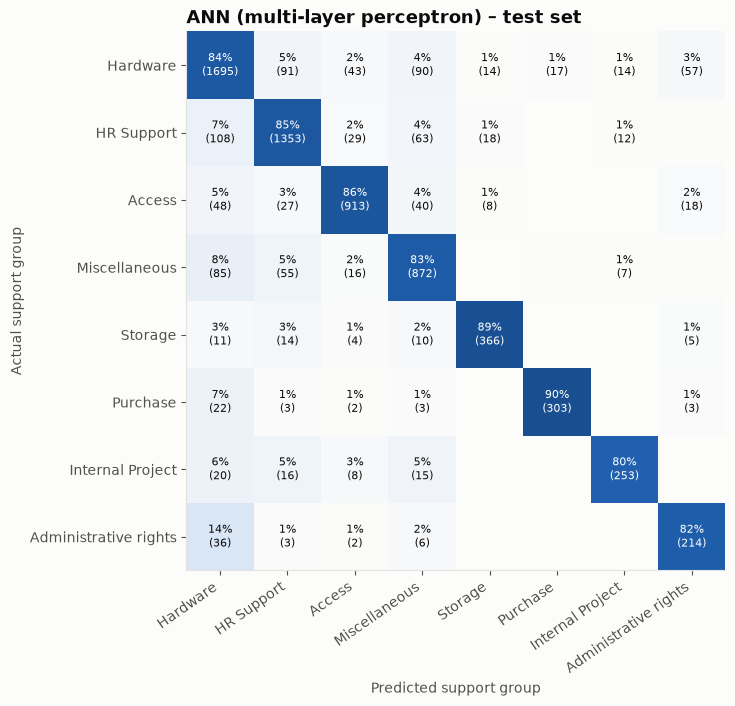

In [9]:
fig, cm = plot_confusion_matrix(test.label, test_pred, "ANN (multi-layer perceptron) – test set", "14_ann_confusion_matrix")
plt.show()

## 6. Sanity check on new tickets

In [10]:
from src.preprocess import clean_text
reloaded = keras.models.load_model(PROJECT_ROOT / "models" / "ann_mlp.keras")
demo = ["My laptop screen is flickering and the docking station does not detect the monitor",
        "Please raise a PO for two new headsets, purchase approved by my manager",
        "I cannot open Confluence, it says my account has no access",
        "Please increase the size of my shared folder, it is full"]
p = reloaded.predict(tf.constant([clean_text(t) for t in demo]), verbose=0)
pd.DataFrame({"ticket": demo, "prediction": np.array(LABELS)[p.argmax(1)], "confidence": p.max(1).round(3)})

,ticket,prediction,confidence
0,My laptop screen is flickering and the docking...,Hardware,0.979
1,"Please raise a PO for two new headsets, purcha...",Miscellaneous,0.489
2,"I cannot open Confluence, it says my account h...",Access,0.987
3,"Please increase the size of my shared folder, ...",Storage,1.000
